In [1]:
from pathlib import Path
import os, json, random, subprocess

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import tensorflow as tf
import cv2

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import (average_precision_score, roc_auc_score, precision_recall_curve,
                             recall_score, precision_score, confusion_matrix, ConfusionMatrixDisplay)

print(f"Tensorflow:{tf.__version__}, OpenCV:{cv2.__version__}")
print(f"GPU:{tf.config.list_physical_devices("GPU")}")

Tensorflow:2.21.0, OpenCV:5.0.0
GPU:[PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [2]:
SEED = 42
IMG_SIZE = 224
DEFECT_CUTOFF = 0.5
BATCH_SIZE = 32
EPOCHS = 30
LR = 1e-3

OUT_DIR = Path("outputs"); OUT_DIR.mkdir(parents=True,exist_ok=True)

def set_seeds(seed=SEED):
  random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)
  os.environ["PYTHON_HASH_SEED"] = str(SEED)
set_seeds()

In [3]:
# get data from GitHub repo
REPO_DIR = Path("elpv-dataset")
if not REPO_DIR.exists():
    subprocess.run(["git", "clone", "--depth", "1",
                    "https://github.com/zae-bayern/elpv-dataset.git", str(REPO_DIR)], check=True)

# The repo stores data under src/elpv_dataset/data
DATA_DIR = next(p for p in [REPO_DIR / "src/elpv_dataset/data", REPO_DIR] if (p / "labels.csv").exists())
print("Data directory:", DATA_DIR)


Data directory: elpv-dataset/src/elpv_dataset/data


# 1. Loading and Exploring the Data

In [4]:
df = pd.read_csv(DATA_DIR / 'labels.csv', sep=r"\s+", header=None, names=['path', 'prob', 'type'])

print(f"Dataset rows and columns: {df.shape}")
df.head(3)

Dataset rows and columns: (2624, 3)


,path,prob,type
0,images/cell0001.png,1.0,mono
1,images/cell0002.png,1.0,mono
2,images/cell0003.png,1.0,mono


In [5]:
df['prob'] = round(df['prob'],2)
df['label'] = (df['prob'] >= DEFECT_CUTOFF).astype(int) # 1 = defective

df['strata'] = df['label'].astype(str) + '_' + df['type']
df['filepath'] = df['path'].apply(lambda p : str(DATA_DIR / p))

display(pd.crosstab(df['prob'], df['type'], margins=True))
display(pd.crosstab(df['label'], df['type'], margins=True, normalize='columns').round(3))

print(f"Defect rate: {df.label.mean():.1%}  Non-defect rate: {1-df.label.mean():.1%} ")

type,mono,poly,All
prob,,,
0.0,588,920,1508
0.33,117,178,295
0.67,56,50,106
1.0,313,402,715
All,1074,1550,2624


type,mono,poly,All
label,,,
0,0.656,0.708,0.687
1,0.344,0.292,0.313


Defect rate: 31.3%  Non-defect rate: 68.7% 


# 2. Analysis raw image


## 2.1 Cell type and defect probability

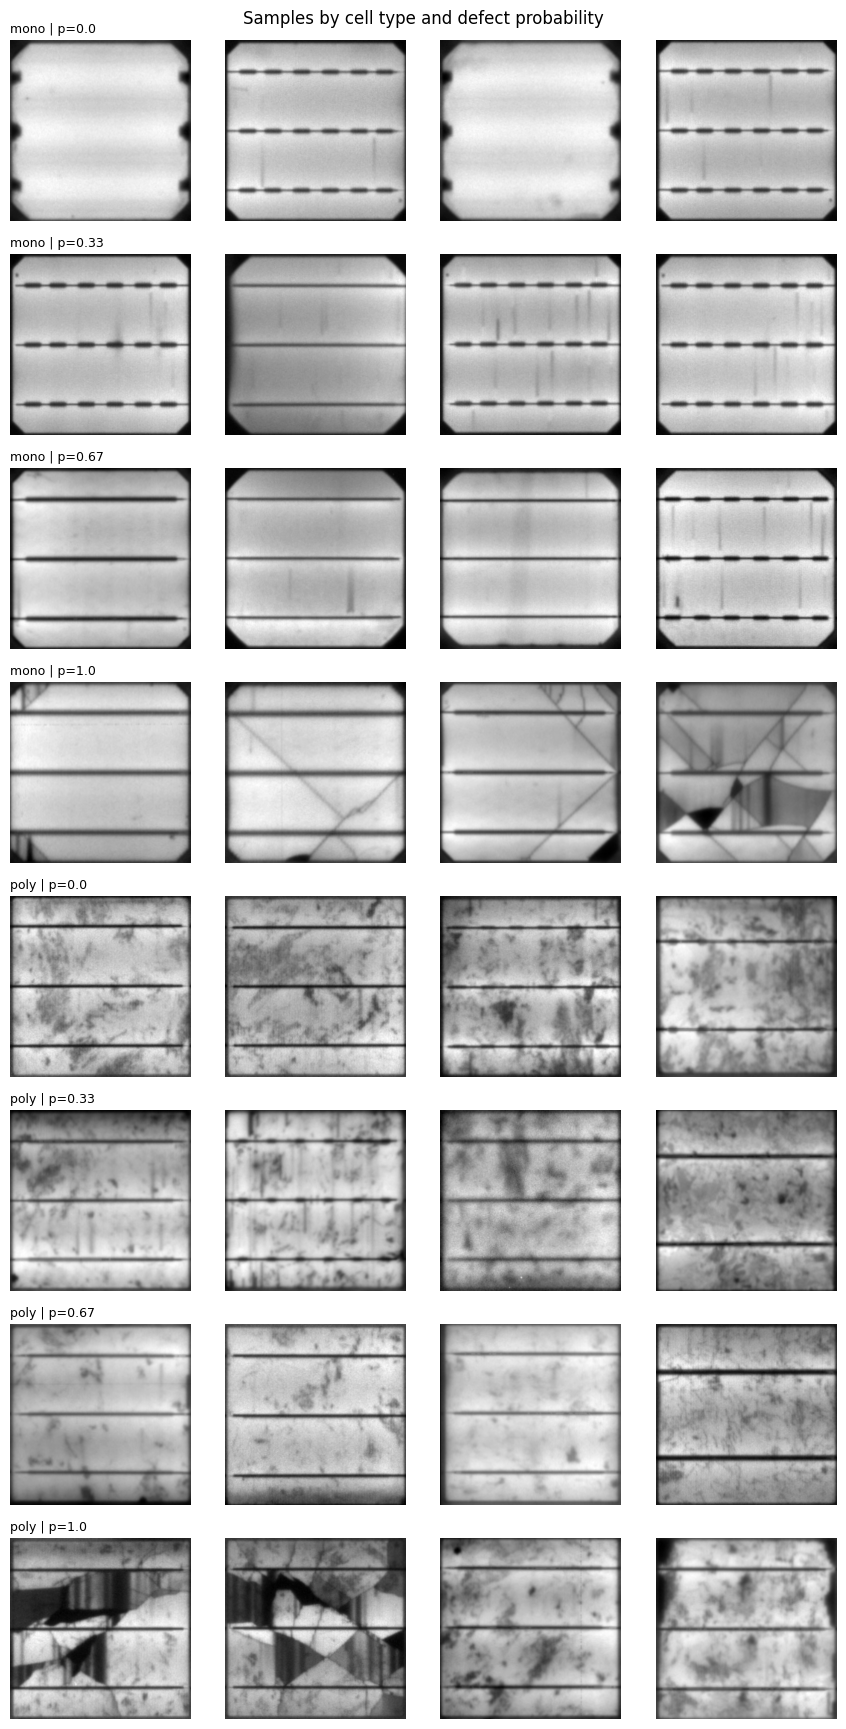

In [6]:
def show_defect_by_celltype(df, n_per_group=4, title=""):
    groups = df.groupby(["type", "prob"])
    fig, axes = plt.subplots(len(groups), n_per_group, figsize=(2.2 * n_per_group, 2.2 * len(groups)))

    for r, ((t, p), g) in enumerate(groups):
        for c, (_, row) in enumerate(g.sample(min(n_per_group, len(g)), random_state=SEED).iterrows()):
            axes[r, c].imshow(cv2.imread(row.filepath, cv2.IMREAD_GRAYSCALE), cmap="gray")
            axes[r, c].axis("off")
        axes[r, 0].set_title(f"{t} | p={p}", fontsize=9, loc="left")
    fig.suptitle(title); plt.tight_layout(); plt.show()


show_defect_by_celltype(df, title="Samples by cell type and defect probability")

## 2.2 Image intensity statistics

mean_int  std_int
type label                   
mono 0         164.2     29.3
     1         141.0     29.7
poly 0         157.5     28.5
     1         129.4     29.6

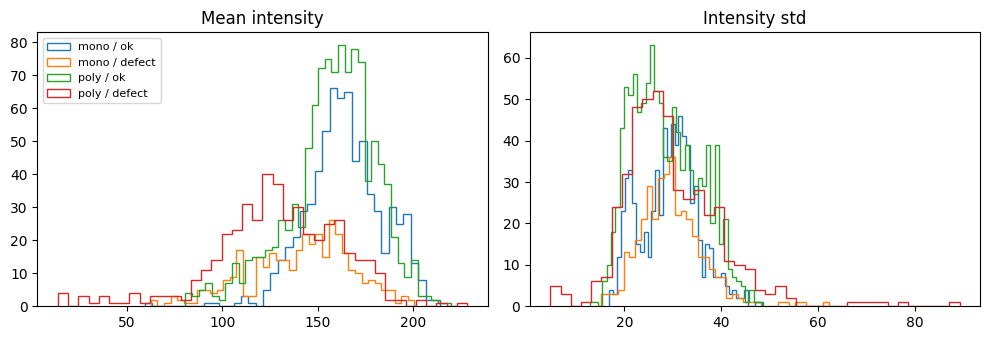

In [7]:
# Intensity statistics: mono vs poly, non-defective vs defective
def show_stats_summary(fp):
    im = cv2.imread(fp, cv2.IMREAD_GRAYSCALE)
    return im.mean(), im.std()



df[["mean_int", "std_int"]] = np.array([show_stats_summary(fp) for fp in df.filepath])
display(df.groupby(["type", "label"])[["mean_int", "std_int"]].mean().round(1))


fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
for t in ["mono", "poly"]:
    for lbl, ls in [(0, "-"), (1, "--")]:
        d = df[(df.type == t) & (df.label == lbl)]
        ax[0].hist(d.mean_int, bins=40, histtype="step", ls=ls, label=f"{t} / {'defect' if lbl else 'ok'}")
        ax[1].hist(d.std_int, bins=40, histtype="step", ls=ls, label=f"{t} / {'defect' if lbl else 'ok'}")
ax[0].set_title("Mean intensity"); ax[1].set_title("Intensity std"); ax[0].legend(fontsize=8)
plt.tight_layout(); plt.show()

# 3. Split data (raw images)

In [8]:
# stratified split (defect × cell type)
# get training set
train_df, temp_df = train_test_split(df, test_size=0.30, stratify=df["strata"], random_state=SEED)

# get validation and test set
val_df, test_df = train_test_split(temp_df, test_size=0.50, stratify=temp_df["strata"], random_state=SEED)


for name, d in [("train", train_df), ("val", val_df), ("test", test_df)]:
    print(f"{name:5s} n={len(d):4d} , defect rate={d.label.mean():.3f} , poly defect rate={(d.type=='poly').mean():.3f} , mono defect rate={(d.type=='mono').mean():.3f}")


# save splitted dataset
splits = pd.concat([train_df.assign(split="train"), val_df.assign(split="val"), test_df.assign(split="test")])
splits[["path", "prob", "type", "label", "split"]].to_csv("outputs/splits.csv", index=False)
print("Saved outputs/splits.csv")

train n=1836 , defect rate=0.313 , poly defect rate=0.590 , mono defect rate=0.410
val   n= 394 , defect rate=0.315 , poly defect rate=0.591 , mono defect rate=0.409
test  n= 394 , defect rate=0.312 , poly defect rate=0.591 , mono defect rate=0.409
Saved outputs/splits.csv


# 4. OpenCV preprocessing
EL images vary in exposure between modules.
**CLAHE** (Contrast Limited Adaptive Histogram Equalization) normalises local contrast so faint cracks stand out,
and a light **median blur** removes salt-and-pepper sensor noise without smearing thin crack lines.

In [9]:
CLAHE = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))

def preprocess(fp, size=IMG_SIZE):
    """Read EL cell image -> CLAHE -> median denoise -> resize. Returns uint8 HxW."""
    im = cv2.imread(fp, cv2.IMREAD_GRAYSCALE)
    im = CLAHE.apply(im)
    im = cv2.medianBlur(im, 3)
    return cv2.resize(im, (size, size), interpolation=cv2.INTER_AREA)


## 4.1 Cell samples of before and after OpenCV preprocessed

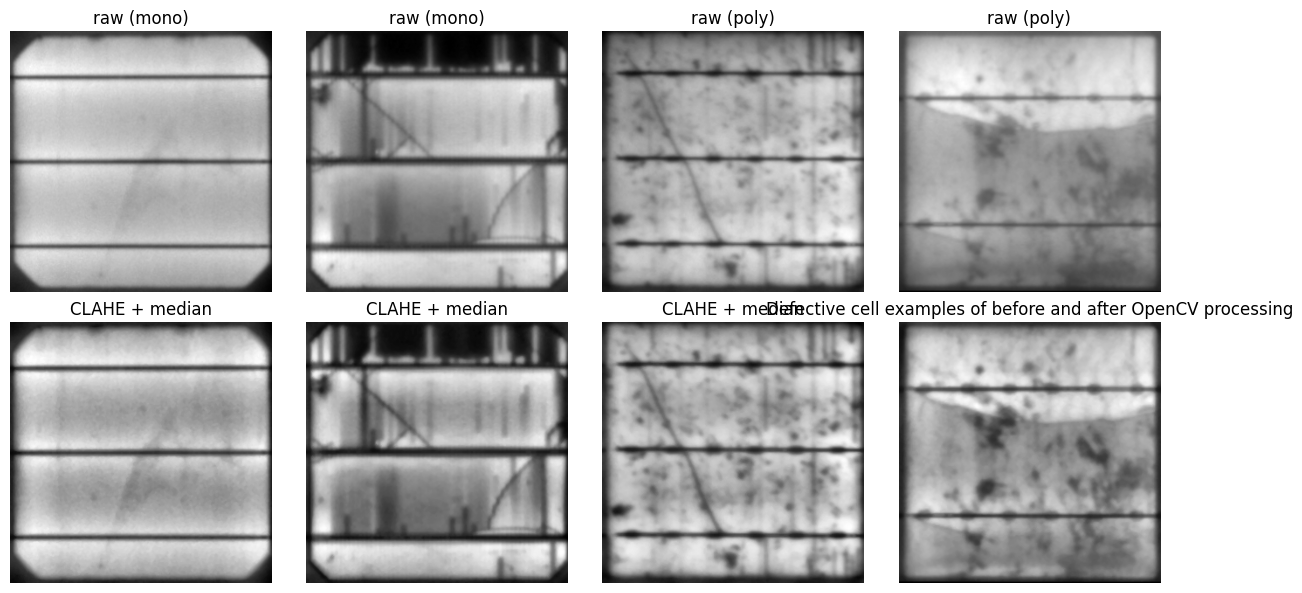

In [10]:
# show before / after on defective examples
ex = df[df.label == 1].groupby("type").sample(2, random_state=SEED)

fig, axes = plt.subplots(2, len(ex), figsize=(3 * len(ex), 6))
for i, (_, row) in enumerate(ex.iterrows()):
    axes[0, i].imshow(cv2.imread(row.filepath, cv2.IMREAD_GRAYSCALE), cmap="gray"); axes[0, i].set_title(f"raw ({row.type})")
    axes[1, i].imshow(preprocess(row.filepath, 300), cmap="gray"); axes[1, i].set_title("CLAHE + median")
    axes[0, i].axis("off"); axes[1, i].axis("off")

plt.title('Defective cell examples of before and after OpenCV processing'); plt.tight_layout(); plt.show()

## 4.2 Load preprocessed data

In [11]:
# after OpenCV preprocessed once and cache in memory (2,624 x 224 x 224 uint8 ≈ 130 MB)
def load_preprocessed_data(d):
    X = np.stack([preprocess(fp) for fp in d.filepath])
    return X, d["label"].values, d["type"].values


X_train, y_train, celltype_train = load_preprocessed_data(train_df)
X_val, y_val, celltype_val = load_preprocessed_data(val_df)
X_test, y_test, celltype_test = load_preprocessed_data(test_df)

print(f"X_train shape: {X_train.shape}, X_val shape: {X_val.shape}, X_test shape: {X_test.shape}")

X_train shape: (1836, 224, 224), X_val shape: (394, 224, 224), X_test shape: (394, 224, 224)


# 5. Implementing the Neural Network

## 5.1 Basic CNN Model

In [21]:
# build Basic CNN model
def build_cnn_model(img_size):

    # Build the model architecture
    inp = tf.keras.Input((img_size, img_size, 1))
    x = inp
    for f in [32, 64, 128, 256]:
        x = tf.keras.layers.Conv2D(f, 3, padding="same", use_bias=False)(x)
        x = tf.keras.layers.BatchNormalization()(x)
        x = tf.keras.layers.ReLU()(x)
        x = tf.keras.layers.MaxPooling2D()(x)
    x = tf.keras.layers.GlobalAveragePooling2D()(x)
    x = tf.keras.layers.Dropout(0.3)(x)
    out = tf.keras.layers.Dense(1, activation="sigmoid")(x)
    model_cnn = tf.keras.Model(inp, out, name="small_cnn")

    # Compile the model
    model_cnn.compile(optimizer=tf.keras.optimizers.Adam(LR), loss="binary_crossentropy",
                metrics=[tf.keras.metrics.AUC(curve="PR", name="pr_auc"),
                        tf.keras.metrics.Recall(name="recall"), tf.keras.metrics.Precision(name="precision")])
    return model_cnn


In [22]:
# build basic small cnn model
model_cnn = build_cnn_model(IMG_SIZE)

# 5.2 Save model for experiments

In [23]:
model_cnn.save("outputs/basic_cnn.keras")
print("Saved outputs/basic_cnn.keras")

Saved outputs/basic_cnn.keras
